# Chapter 3 — Perceptrons

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/03_perceptron.ipynb)

*Companion notebook for Stone (2020), Chapter 3, using `scripts/perceptron.py`.*

A perceptron (Fig 3.1) is a linear associative network whose single output unit has a threshold
activation (Fig 3.3, Eq 3.3):

$$u = \mathbf{w}\cdot\mathbf{x}, \qquad y = \begin{cases} +1 & u > \theta \\ -1 & \text{otherwise.}\end{cases}$$

The **perceptron learning rule** (Eq 3.4) leaves $\mathbf{w}$ unchanged for correctly classified inputs, and for
a misclassified input $\mathbf{x}$ with target $\mathsf{y}\in\{-1,+1\}$ sets

$$\Delta\mathbf{w} = \epsilon\, \mathsf{y}\, \mathbf{x} .$$

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

> **Notation note (no sign error in Eq 3.4).** The book distinguishes the *target* (a sans-serif
> $\mathsf{y}$) from the *actual output* (an italic $y$), see Section 2.3. Eq 3.4 says: if the target is $-1$
> but the output is $+1$, then $\Delta\mathbf{w} = -\epsilon\mathbf{x}$; if the target is $+1$ but the
> output is $-1$, then $\Delta\mathbf{w} = +\epsilon\mathbf{x}$. In both cases this is
> $\Delta\mathbf{w} = \epsilon\cdot\text{target}\cdot\mathbf{x}$ on misclassified inputs — the standard
> perceptron rule. In plain-text copies of the book the two fonts look identical, which can make the rule
> appear to have its signs inverted; it does not.

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scripts.perceptron import Perceptron
from aie.data import two_class_2d, xor_dataset
from aie.plotting import plot_decision_boundary_2d

## Two linearly separable classes (Section 3.2, Figs 3.2 & 3.4)

As in the book: $N=200$ points, $N_1=100$ in class $C_1$ ($x_2 \le 0$, target $-1$) and $N_2=100$ in
class $C_2$ ($x_2>0$, target $+1$), learning rate $\epsilon=0.01$ and threshold $\theta=0$ (no bias).

epochs used: 13  final w: [-0.0023  0.0785]  accuracy: 1.0


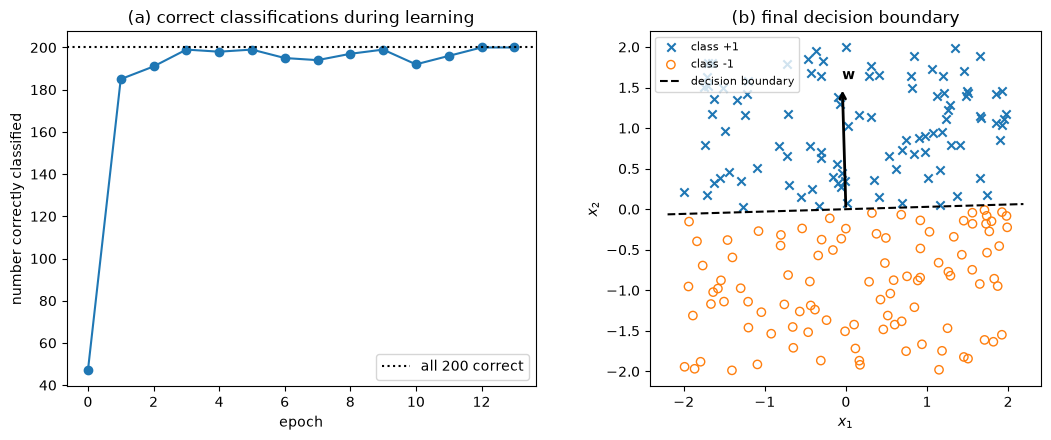

In [3]:
X, t = two_class_2d(n_per_class=100, seed=0)
p = Perceptron(n_inputs=2, lr=0.01, seed=0).fit(X, t, n_epochs=100)
print("epochs used:", len(p.correct_per_epoch), " final w:", p.w.round(4),
      " accuracy:", np.mean(p.predict(X) == t))

w0 = Perceptron(n_inputs=2, lr=0.01, seed=0).w
correct0 = int(np.sum(Perceptron(2, seed=0).predict(X) == t))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(range(len(p.correct_per_epoch) + 1), [correct0] + p.correct_per_epoch, "o-")
axes[0].axhline(len(t), color="k", ls=":", label="all 200 correct")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("number correctly classified")
axes[0].set_title("(a) correct classifications during learning"); axes[0].legend()
plot_decision_boundary_2d(X, t, p.w, ax=axes[1], title="(b) final decision boundary")
wn = p.w / np.linalg.norm(p.w)
axes[1].annotate("", xy=1.5 * wn, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2, color="k"))
axes[1].text(*(1.6 * wn), "$\\mathbf{w}$")
fig.tight_layout()

As in Figure 3.4b, the final weight vector is nearly vertical, and the decision boundary $\mathbf{w}\cdot\mathbf{x}=0$
is the line through the origin perpendicular to $\mathbf{w}$.

### The decision boundary during learning

Because `fit` is deterministic for a given seed, training for $k$ epochs reproduces the state after epoch $k$.
To see the boundary rotating we start from a deliberately bad weight vector and use online updates.

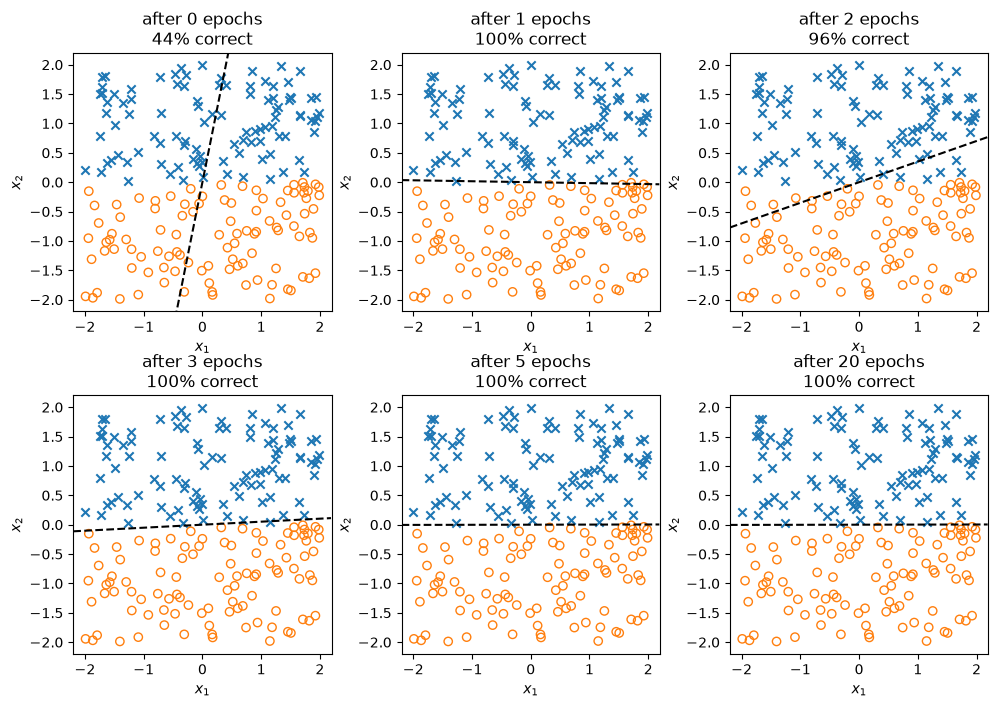

In [4]:
snaps = [0, 1, 2, 3, 5, 20]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, k in zip(axes.flat, snaps):
    q = Perceptron(2, lr=0.01, seed=0)
    q.w[:] = [0.1, -0.02]                 # boundary almost vertical: about half the points wrong
    if k:
        q.fit(X, t, n_epochs=k)
    acc = np.mean(q.predict(X) == t)
    plot_decision_boundary_2d(X, t, q.w, ax=ax, title=f"after {k} epochs\n{acc:.0%} correct")
    ax.legend().remove(); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
fig.tight_layout()

## Thresholds: boundaries that do not pass through the origin

With $\theta=0$ the decision boundary $\mathbf{w}\cdot\mathbf{x}=0$ must pass through the origin. If we shift the
data up by one unit (so the true boundary is $x_2 = 1$), no such line can separate the classes. Treating the
threshold as an extra weight attached to a constant input of $-1$ (`bias=True`, as in Section 5.2 / Fig 4.2)
gives the boundary $w_1x_1 + w_2x_2 = \theta$, which can be anywhere in the plane.

learned threshold theta = 0.094  boundary x2 ≈ 0.983


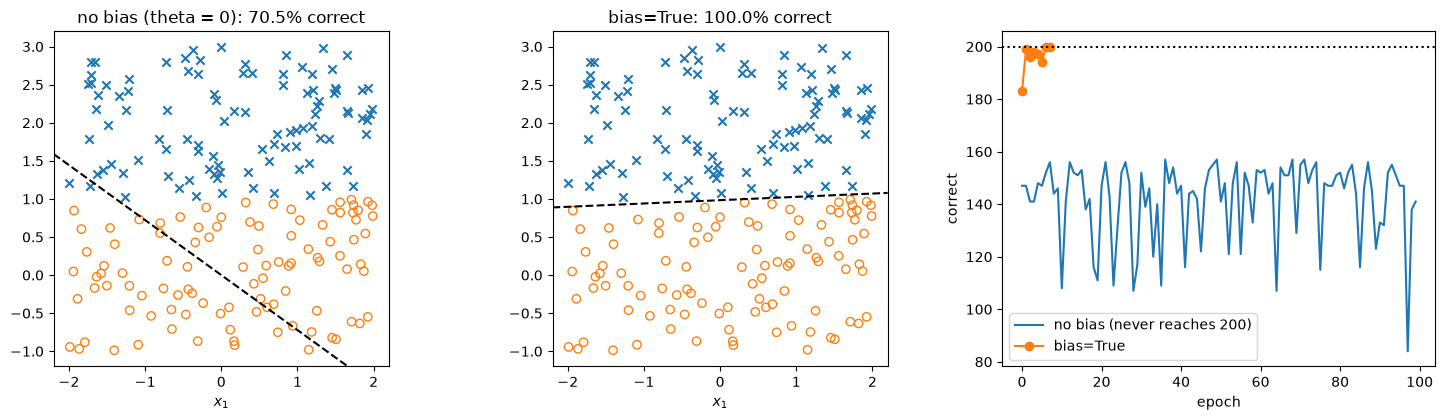

In [5]:
Xs = X + np.array([0.0, 1.0])
p_nb = Perceptron(2, lr=0.01, seed=0).fit(Xs, t, n_epochs=100)
p_b = Perceptron(2, lr=0.01, seed=0, bias=True).fit(Xs, t, n_epochs=100)

def boundary(ax, w, xs, **kw):          # w1 x1 + w2 x2 - theta = 0
    th = w[2] if len(w) == 3 else 0.0
    ax.plot(xs, (th - w[0] * xs) / w[1], **kw)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
xs = np.linspace(-2.2, 2.2, 10)
for ax, q, ttl in [(axes[0], p_nb, "no bias (theta = 0)"), (axes[1], p_b, "bias=True")]:
    pos = t > 0
    ax.scatter(*Xs[pos].T, marker="x", color="C0"); ax.scatter(*Xs[~pos].T, facecolors="none", edgecolors="C1")
    boundary(ax, q.w, xs, color="k", ls="--")
    ax.set_title(f"{ttl}: {np.mean(q.predict(Xs) == t):.1%} correct")
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.2, 3.2); ax.set_aspect("equal"); ax.set_xlabel("$x_1$")
axes[2].plot(p_nb.correct_per_epoch, label="no bias (never reaches 200)")
axes[2].plot(p_b.correct_per_epoch, "o-", label="bias=True")
axes[2].axhline(200, color="k", ls=":"); axes[2].set_xlabel("epoch"); axes[2].set_ylabel("correct")
axes[2].legend(); fig.tight_layout()
print("learned threshold theta =", p_b.w[2].round(4), " boundary x2 ≈", (p_b.w[2] / p_b.w[1]).round(3))

## Failure on exclusive OR (Section 3.3)

The XOR associations (Eq 3.5–3.6) put class $C_1$ in two opposite quadrants and $C_2$ in the other two
(Fig 3.6). No straight line separates them, so the perceptron can never classify all four correctly: at
best 3 of 4, and the weights keep cycling because some input is always misclassified (the perceptron
convergence theorem only applies to linearly separable data).

errors in the last 10 epochs: [2, 3, 4, 2, 3, 3, 4, 3, 2, 3]
max correct in any epoch: 3 of 4
best final score over 20 random seeds: 3 of 4


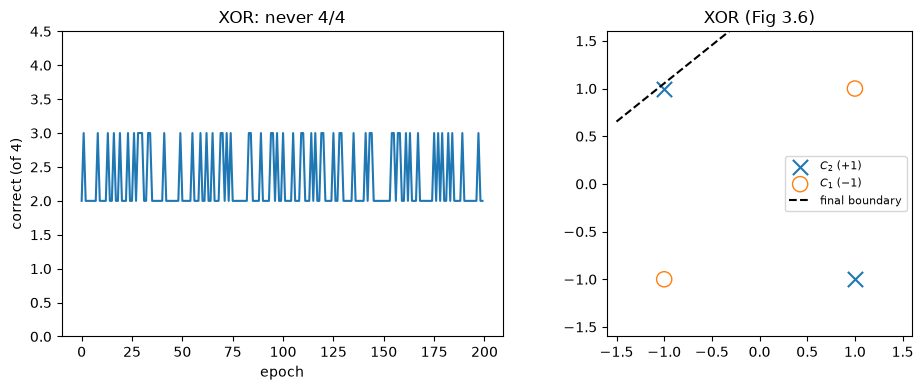

In [6]:
Xx, tx = xor_dataset()
px = Perceptron(2, lr=0.01, seed=0, bias=True).fit(Xx, tx, n_epochs=200)
print("errors in the last 10 epochs:", px.errors_per_epoch[-10:])
print("max correct in any epoch:", max(px.correct_per_epoch), "of 4")
best = max(Perceptron(2, lr=0.01, seed=s, bias=True).fit(Xx, tx, 200).correct_per_epoch[-1]
           for s in range(20))
print("best final score over 20 random seeds:", best, "of 4")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(px.correct_per_epoch); axes[0].set_ylim(0, 4.5)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("correct (of 4)"); axes[0].set_title("XOR: never 4/4")
pos = tx > 0
axes[1].scatter(*Xx[pos].T, marker="x", s=120, color="C0", label="$C_2$ (+1)")
axes[1].scatter(*Xx[~pos].T, s=120, facecolors="none", edgecolors="C1", label="$C_1$ (−1)")
boundary(axes[1], px.w, np.linspace(-1.5, 1.5, 10), color="k", ls="--", label="final boundary")
axes[1].set_xlim(-1.6, 1.6); axes[1].set_ylim(-1.6, 1.6); axes[1].set_aspect("equal")
axes[1].legend(fontsize=8); axes[1].set_title("XOR (Fig 3.6)")
fig.tight_layout()

## Summary

* The perceptron rule $\Delta\mathbf{w}=\epsilon\,\mathsf{y}\,\mathbf{x}$ (misclassified inputs only) finds a separating
  line whenever one exists.
* Without a threshold/bias the line must pass through the origin; a bias input of $-1$ removes that restriction.
* A perceptron can only draw straight-line (hyperplane) boundaries, so it cannot solve XOR — the result
  (Minsky & Papert, 1969) that triggered the first neural-network winter, and which hidden units fix in Chapter 4.